<a href="https://colab.research.google.com/github/shiv2899/heartbeat-classifier/blob/main/heartbeat_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
# 1. wfdb install karo - ECG padhne ke liye
!pip install -q wfdb numpy pandas

import wfdb
import numpy as np
import pandas as pd
import os

base = "/content/drive/MyDrive/heartbeat-classifier"
os.makedirs(f"{base}/data", exist_ok=True)

# 2. Kaun se records lene hai - 100 se 109 tak, ye sabse famous hai
records = ['100', '101', '102', '103', '105', '106', '107', '108', '109', '111', '112', '113', '114', '115', '116', '117', '119', '121', '122', '123', '124', '200', '201', '202', '203', '205', '207', '208', '209', '210', '212', '213', '214', '215', '217', '219', '220', '221', '222', '223', '228', '230', '231', '232', '233', '234']

# AAMI Classes: N, S, V, F, Q
# MIT-BIH symbols ko 5 class me badlo
symbol_to_class = {
    'N': 0, 'L': 0, 'R': 0, 'e': 0, 'j': 0,  # Normal
    'A': 1, 'a': 1, 'J': 1, 'S': 1,  # Supraventricular
    'V': 2, 'E': 2,  # Ventricular
    'F': 3,  # Fusion
    '/': 4, 'f': 4, 'Q': 4  # Unknown
}

X_list = []
y_list = []

print("Downloading from PhysioNet... thoda time lagega, 1-2 min")
for rec in records:
    try:
        # Signal + Annotation download karo
        signals, fields = wfdb.rdsamp(rec, pn_dir='mitdb')
        ann = wfdb.rdann(rec, 'atr', pn_dir='mitdb')
        ecg = signals[:, 0]  # Lead 1 hi lenge
        fs = fields['fs']  # 360 Hz

        for i, sym in enumerate(ann.symbol):
            if sym not in symbol_to_class:
                continue
            peak = ann.sample[i]
            # Har heartbeat ke aage-peeche 187 samples kaat lo
            start = peak - 90
            end = peak + 97
            if start < 0 or end >= len(ecg):
                continue
            beat = ecg[start:end]
            X_list.append(beat)
            y_list.append(symbol_to_class[sym])
        print(f"Record {rec} done, total beats: {len(X_list)}")
    except Exception as e:
        print(f"Record {rec} skip: {e}")

X = np.array(X_list)
y = np.array(y_list)
print("\nTotal beats:", X.shape)
print("Har class kitni hai:", np.unique(y, return_counts=True))

# 3. Train-Test me baanto aur CSV me save karo
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

train_df = pd.DataFrame(X_train)
train_df[187] = y_train
test_df = pd.DataFrame(X_test)
test_df[187] = y_test

train_df.to_csv(f"{base}/data/mitbih_train.csv", header=False, index=False)
test_df.to_csv(f"{base}/data/mitbih_test.csv", header=False, index=False)

print("\nSaved!")
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

Record 100 done, total beats: 2271
Record 101 done, total beats: 4135
Record 102 done, total beats: 6322
Record 103 done, total beats: 8406
Record 105 done, total beats: 10978
Record 106 done, total beats: 13005
Record 107 done, total beats: 15142
Record 108 done, total beats: 16904
Record 109 done, total beats: 19435
Record 111 done, total beats: 21559
Record 112 done, total beats: 24098
Record 113 done, total beats: 25892
Record 114 done, total beats: 27771
Record 115 done, total beats: 29723
Record 116 done, total beats: 32134
Record 117 done, total beats: 33668
Record 119 done, total beats: 35655
Record 121 done, total beats: 37518
Record 122 done, total beats: 39993
Record 123 done, total beats: 41510
Record 124 done, total beats: 43129
Record 200 done, total beats: 45729
Record 201 done, total beats: 47692
Record 202 done, total beats: 49828
Record 203 done, total beats: 52808
Record 205 done, total beats: 55464
Record 207 done, total beats: 57323
Record 208 done, total beats: 60

Train: (83968, 187) Test: (20993, 187)
Total Params: 0.413253 M
Class weights: [ 0.23779559  7.81824953  2.90899013 26.15825545  3.51110182]

Training Start...
Epoch 1/15 | Loss: 0.4040 | Test Acc: 91.39%
Epoch 2/15 | Loss: 0.2343 | Test Acc: 90.07%
Epoch 3/15 | Loss: 0.1887 | Test Acc: 92.62%
Epoch 4/15 | Loss: 0.1675 | Test Acc: 96.21%
Epoch 5/15 | Loss: 0.1413 | Test Acc: 95.89%
Epoch 6/15 | Loss: 0.1209 | Test Acc: 94.86%
Epoch 7/15 | Loss: 0.1208 | Test Acc: 92.00%
Epoch 8/15 | Loss: 0.1039 | Test Acc: 93.93%
Epoch 9/15 | Loss: 0.0964 | Test Acc: 96.89%
Epoch 10/15 | Loss: 0.0897 | Test Acc: 95.27%
Epoch 11/15 | Loss: 0.0879 | Test Acc: 95.63%
Epoch 12/15 | Loss: 0.0733 | Test Acc: 97.81%
Epoch 13/15 | Loss: 0.0737 | Test Acc: 97.51%
Epoch 14/15 | Loss: 0.0710 | Test Acc: 95.04%
Epoch 15/15 | Loss: 0.0657 | Test Acc: 96.91%
Model Saved!

--- Classification Report ---
              precision    recall  f1-score   support

           N       1.00      0.97      0.98     17656
      

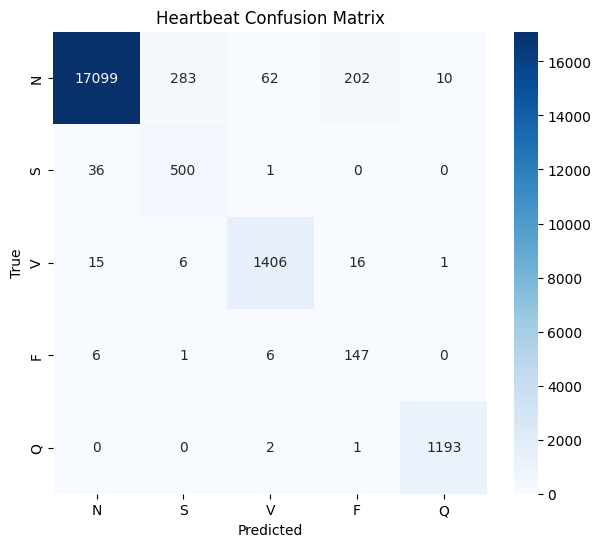

In [10]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

base = "/content/drive/MyDrive/heartbeat-classifier"

# --- 1. Data Load ---
train = pd.read_csv(f"{base}/data/mitbih_train.csv", header=None).values
test = pd.read_csv(f"{base}/data/mitbih_test.csv", header=None).values

X_train, y_train = train[:, :187], train[:, 187].astype(int)
X_test, y_test = test[:, :187], test[:, 187].astype(int)
print("Train:", X_train.shape, "Test:", X_test.shape)

# Normalize - har beat ko 0-1 me lao
X_train = (X_train - X_train.mean(axis=1, keepdims=True)) / (X_train.std(axis=1, keepdims=True) + 1e-8)
X_test = (X_test - X_test.mean(axis=1, keepdims=True)) / (X_test.std(axis=1, keepdims=True) + 1e-8)

X_train_t = torch.tensor(X_train, dtype=torch.float32).unsqueeze(1)  # (N, 1, 187)
X_test_t = torch.tensor(X_test, dtype=torch.float32).unsqueeze(1)
y_train_t = torch.tensor(y_train, dtype=torch.long)
y_test_t = torch.tensor(y_test, dtype=torch.long)

# --- 2. 1D-CNN Model ---
class HeartbeatCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv1d(1, 32, kernel_size=5, padding=2)
        self.bn1 = nn.BatchNorm1d(32)
        self.conv2 = nn.Conv1d(32, 64, kernel_size=5, padding=2)
        self.bn2 = nn.BatchNorm1d(64)
        self.conv3 = nn.Conv1d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm1d(128)
        self.pool = nn.MaxPool1d(2)
        self.dropout = nn.Dropout(0.3)
        # 187 -> 93 -> 46 -> 23
        self.fc1 = nn.Linear(128*23, 128)
        self.fc2 = nn.Linear(128, 5)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))  # 187->93
        x = self.pool(F.relu(self.bn2(self.conv2(x))))  # 93->46
        x = self.pool(F.relu(self.bn3(self.conv3(x))))  # 46->23
        x = x.view(x.size(0), -1)
        x = self.dropout(F.relu(self.fc1(x)))
        x = self.fc2(x)
        return x

torch.manual_seed(42)
model = HeartbeatCNN()
print("Total Params:", sum(p.numel() for p in model.parameters())/1e6, "M")

# Class imbalance ke liye weights - chhoti class ko jyada weight
from sklearn.utils.class_weight import compute_class_weight
weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
print("Class weights:", weights)
criterion = nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float32))
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# --- 3. Training ---
batch_size = 256
epochs = 15
n = len(X_train_t)
print("\nTraining Start...")

for epoch in range(epochs):
    model.train()
    perm = torch.randperm(n)
    total_loss = 0
    for i in range(0, n, batch_size):
        idx = perm[i:i+batch_size]
        xb, yb = X_train_t[idx], y_train_t[idx]
        logits = model(xb)
        loss = criterion(logits, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(idx)
    # Val
    model.eval()
    with torch.no_grad():
        preds = model(X_test_t).argmax(dim=1)
        acc = (preds == y_test_t).float().mean().item()
    print(f"Epoch {epoch+1}/{epochs} | Loss: {total_loss/n:.4f} | Test Acc: {acc*100:.2f}%")

# --- 4. Save + Report ---
torch.save(model.state_dict(), f"{base}/checkpoints/heartbeat_cnn.pt")
print("Model Saved!")

model.eval()
with torch.no_grad():
    preds = model(X_test_t).argmax(dim=1).numpy()

print("\n--- Classification Report ---")
print(classification_report(y_test, preds, target_names=['N','S','V','F','Q']))

# Confusion Matrix
cm = confusion_matrix(y_test, preds)
plt.figure(figsize=(7,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['N','S','V','F','Q'], yticklabels=['N','S','V','F','Q'])
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Heartbeat Confusion Matrix')
plt.savefig(f"{base}/results/confusion_matrix.png", dpi=150)
plt.show()